# Assignment: Recommender Systems, Clustering and PCA

<div class="alert alert-danger" role="alert">
  Note: <br>
    1. Only modify the area marked by "YOUR CODE STARTS HERE" and "YOUR CODE ENDS HERE" markers<br>
    2. If you are working locally, the data files should be in the same directory as your Assignment4.ipynb Notebook.<br>
</div>

# Exercise: Recommender System

In this exercise, we provide you with an implementation of a collaborative-filtering recommender system. Your task is to train the recommender system on the MovieLens dataset with 100k ratings: https://grouplens.org/datasets/movielens/100k/. When you unzip the zip assignment file, the dataset will be in the same directory of your assignment.

## MovieLens Dataset Exploration and Preparation

The below code demonstrates the initial steps of exploring and preparing the MovieLens dataset. The dataset contains information about users, movies, and ratings.

- Users Data: Contains information about users such as user ID, age, sex, occupation, and zip code.
- Ratings Data: Includes user ratings for movies, along with timestamps.
- Movies Data: Provides details about movies, including movie ID, title, release date, video release date, and IMDb URL.

**Merging**: Combines information from movies, ratings, and users into a single dataframe (lens).

**Movie Index Dictionary**: Maps movie titles to their corresponding movie IDs (`movie_idx`) and vice versa (`idx_movie`). This mapping is useful for easy reference and retrieval of movie information.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')
import os
os.chdir('/content/drive/MyDrive/Colab Notebooks/Assignment 4')

# Reading users file
u_cols = ['user_id', 'age', 'sex', 'occupation', 'zip_code']
users = pd.read_csv('ml-100k/u.user', sep='|', names=u_cols,
                    encoding='latin-1')
# Reading data file
r_cols = ['user_id', 'movie_id', 'rating', 'unix_timestamp']
ratings = pd.read_csv('ml-100k/u.data', sep='\t', names=r_cols,
                      encoding='latin-1')
# Reading items file
m_cols = ['movie_id', 'title', 'release_date', 'video_release_date', 'imdb_url']
movies = pd.read_csv('ml-100k/u.item', sep='|', names=m_cols, usecols=range(5),
                     encoding='latin-1')
# merging data as one dataframe
movie_ratings = pd.merge(movies, ratings, on='movie_id')
lens = pd.merge(movie_ratings, users,   on='user_id')

movie_idx  = dict(zip(movies['title'],     movies['movie_id']))
idx_movie  = dict(zip(movies['movie_id'],  movies['title']))

Mounted at /content/drive


## Creating User-Item Rating Matrix

Below we create a user-item rating matrix from the MovieLens dataset. The process includes mapping unique user (`user_id`) and movie IDs (`movie_id`), and then constructing a pivot table to form the `rating matrix`.

In [3]:
# unique users ids data
user_map = pd.Series(
    index=np.unique(lens['user_id']),
    data=np.arange(lens['user_id'].nunique()),
    name='user_map')

# unique movies ids data
movie_map = pd.Series(
    index=np.unique(lens['movie_id']),
    data=np.arange(lens['movie_id'].nunique()),
    name='movie_map')
# mapping unique users ids to the lens data
user_inds = lens['user_id'].map(user_map)
# mapping unique movies ids to the lens data
movie_inds = lens['movie_id'].map(movie_map)

# creating a pivot table of user_id, movie_id, and rating
rating_matrix = pd.pivot_table(
    data=lens,
    values='rating',
    index=user_inds,
    columns=movie_inds,
    aggfunc='first',
    fill_value=0
).to_numpy(dtype=int)
rating_matrix

array([[5, 3, 4, ..., 0, 0, 0],
       [4, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [5, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 5, 0, ..., 0, 0, 0]])

## Matrix Factorization
The code defines a class named `MatrixFactorization` to implement matrix factorization for collaborative filtering. This technique is used for predicting user ratings for movies based on latent features.

Parameters:
- `rating_matrix`: The matrix of user ratings (row: user, col: movie).
- `rating_matrix_val`: Validation set for model evaluation.
- `k`: Number of latent features.
- `lmbda`: Regularization parameter.
- `max_epochs`: Maximum number of iterations.
- `lr`: Learning rate

In [4]:
class MatrixFactorization:
    def __init__(
        self,
        rating_matrix: np.ndarray,
        rating_matrix_val: np.ndarray,
        k: int = 5,
        lmbda: float = 0.01,
        max_epochs: int = 50,
        lr: float = 0.01     # ← lowered default LR
    ) -> None:
        self.rating_matrix     = rating_matrix
        self.rating_matrix_val = rating_matrix_val
        self.k                 = k
        self.lmbda             = lmbda
        self.max_epochs        = max_epochs
        self.lr                = lr

        n_users, n_items = rating_matrix.shape

        # ← much smaller initialization
        init_scale = 0.01
        self.U = np.random.normal(scale=init_scale, size=(n_users, k))
        self.V = np.random.normal(scale=init_scale, size=(k, n_items))

        self.b_u = np.zeros(n_users)
        self.b_i = np.zeros(n_items)

        mask = rating_matrix > 0
        self.b = float(rating_matrix[mask].mean()) if mask.any() else 0.0

        self.train_mse_history = []
        self.val_mse_history   = []

    def fit(self) -> "MatrixFactorization":
        users, items = np.nonzero(self.rating_matrix)

        for epoch in range(self.max_epochs):
            for i, j in zip(users, items):
                actual = self.rating_matrix[i, j]
                pred   = self.predict_rating(i, j)
                err    = actual - pred

                # SGD updates
                self.b_u[i] += self.lr * (err - self.lmbda * self.b_u[i])
                self.b_i[j] += self.lr * (err - self.lmbda * self.b_i[j])
                self.U[i, :] += self.lr * (err * self.V[:, j] - self.lmbda * self.U[i, :])
                self.V[:, j] += self.lr * (err * self.U[i, :] - self.lmbda * self.V[:, j])

            full_pred = self.predict()
            train_mse = self._compute_mse(self.rating_matrix,     full_pred)
            val_mse   = self._compute_mse(self.rating_matrix_val, full_pred)

            self.train_mse_history.append(train_mse)
            self.val_mse_history.append(val_mse)

            # if we diverge, stop early
            if np.isnan(train_mse) or np.isinf(train_mse):
                print(f"Stopping at epoch {epoch+1}: train MSE={train_mse}")
                break

        return self

    def _compute_mse(self, truth: np.ndarray, pred: np.ndarray) -> float:
        mask = truth > 0
        if not mask.any():
            raise ValueError("No observed ratings to compute MSE.")
        return float(((truth[mask] - pred[mask]) ** 2).mean())

    def predict_rating(self, i: int, j: int) -> float:
        return (
            self.b
            + self.b_u[i]
            + self.b_i[j]
            + self.U[i, :].dot(self.V[:, j])
        )

    def predict(self) -> np.ndarray:
        return (
            self.b
            + self.b_u[:, np.newaxis]
            + self.b_i[np.newaxis, :]
            + self.U.dot(self.V)
        )

    def plot_loss(self) -> None:
        epochs = np.arange(1, len(self.train_mse_history) + 1)
        plt.plot(epochs, self.train_mse_history, label="Training MSE")
        plt.plot(epochs, self.val_mse_history,   label="Validation MSE")
        plt.xlabel("Epoch")
        plt.ylabel("Mean Squared Error")
        plt.legend()
        plt.tight_layout()
        plt.show()

## Data Splitting for Training and Validation Sets

The code defines a function `create_training_validation_set` to split the given `rating_matrix` into training and validation sets for model evaluation. The splitting is done by randomly selecting a subset of ratings (`20%`) from the original matrix and masking them in the training set.



In [5]:
def create_train_val(ratings, test_frac = 0.2, seed: int = None):
    """
    For each nonzero rating, with probability test_frac
    move it from train -> val.
    """
    rng = np.random.RandomState(seed)
    train = ratings.copy()
    val   = np.zeros_like(ratings)

    # find all the (user, item) pairs that were rated
    users, items = np.nonzero(ratings)
    for u, i in zip(users, items):
        if rng.rand() < test_frac:
            val[u, i] = ratings[u, i]
            train[u, i] = 0

    return train, val


###### YOUR CODE STARTS HERE #####

# Fix a seed for reproducibility.
rating_matrix_train, rating_matrix_val = create_train_val (
    rating_matrix, test_frac=0.2, seed=42
    )


###### YOUR CODE ENDS HERE #####

## Finding Top Similar Movies

`find_top_close_movies` is used to identify the top similar movies to a given movie based on movie filtering.


In [6]:
def find_top_close_movies(
    movie_idx,
    idx_movie,
    pred_ratings,
    movie_name,
    top_n
):
    """
    Find the top_n movies most similar to `movie_name` by
    Pearson-correlation of predicted ratings across users.

    """
    if movie_name not in movie_idx:
        raise KeyError(f"Movie {movie_name!r} not found in your index.")

    # turn the numpy array into a DataFrame
    df = pd.DataFrame(pred_ratings)

    # extract the reference series (all users’ scores for that movie)
    target_col = movie_idx[movie_name]
    target_series = df.iloc[:, target_col]

    # compute Pearson correlation of every other column with the target
    corrs = df.corrwith(target_series, axis=0)

    # drop the movie itself from consideration
    corrs = corrs.drop(labels=target_col)

    # select the top_n highest correlations
    top = corrs.nlargest(top_n)

    # map back to titles
    return [(idx_movie[col], float(score)) for col, score in top.items()]

## Recommending Movies to a User
`recommend_movies_to_user` is used to recommend movies to a given user based user filtering.

In [7]:
def recommend_movies_to_user(idx_movie, pred_rating, user_id):
    """
    For a given user_id, find the 5 users whose predicted-rating
    vectors correlate most with that user, average their ratings,
    and print the top-5 movie titles by that average.
    """
    # turn the prediction matrix into a DataFrame
    df = pd.DataFrame(pred_rating)

    # grab the target user's predicted-rating series
    user_series = df.iloc[user_id]

    # compute user–user Pearson correlations
    sims = df.corrwith(user_series, axis=1)

    # drop the user itself and pick the 5 highest correlations
    top_users = sims.drop(labels=user_id) \
                    .sort_values(ascending=False) \
                    .head(5) \
                    .index

    # average those users' predicted ratings for each movie
    mean_ratings = pred_rating[top_users, :].mean(axis=0)

    # pick the 5 movies with the highest mean rating
    rec_idxs = np.argsort(mean_ratings)[::-1][:5]

    # print their titles
    for m in rec_idxs:
        print(idx_movie[m])

## Matrix Factorization Model with Best Parameters

Instantiates an instance of the `MatrixFactorization` model.

`rating_matrix_training` and `rating_matrix_validation` are matrices representing the training and validation sets, respectively.


In [8]:
###### YOUR CODE STARTS HERE #####
# build the model
model = MatrixFactorization(
    rating_matrix_train,
    rating_matrix_val,
    k=10,
    lmbda= .01,
    max_epochs=20,
    lr=.01
)
# fit your model
model.fit()

# get the full prediction matrix
pred = model.predict()

###### YOUR CODE ENDS HERE #####
# report final MSEs
print("Final train MSE:", model.train_mse_history[-1])
print("Final val   MSE:", model.val_mse_history[-1])

Final train MSE: 0.7342650983313433
Final val   MSE: 0.8547660710995418


Visualize the loss (Mean Squared Error) of the model during training epochs.

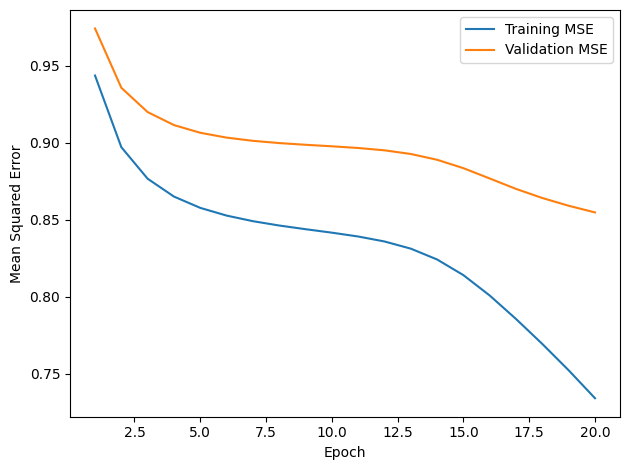

In [9]:
###### YOUR CODE STARTS HERE #####

# plot the loss curve
model.plot_loss()

###### YOUR CODE ENDS HERE #####

Is the model underfitting, overfitting, or neither? Name one change (k, $\lambda$, lr, or epochs) you would try and why.

Answer:
This model is neither underfitting or overfitting, but doing well. Both curves are decreasing, true they are not close to each others, but a good sign is that the training one continue decreasing while the validation decrease is slowing and tends to flatten - it started diverging from the training (if we had more date for training, this validation curve will probably flatten and continue as straight line).

I would add a bit more epochs (not much to avoid overfitting) to enhance training and know how the curves continuities would be like. A complementary change, if we got overfitting, we increase lmbda to add regularization so we guide overfitting away.

#### Comments on analysis

You correctly identified that the model is balanced, with both MSE curves steadily improving and no sharp divergence. The interpretation that it's neither underfitting nor overfitting is spot on. Your suggestion to add a few epochs to observe if the validation loss stabilizes shows good practical thinking.

### Choose a Movie

In [10]:
ref_title = idx_movie[50]  # choose a valid id (≤ max(idx_movie.keys()))
print(f"Movie: {ref_title}\n\nRecommended Movies:\n")

###### YOUR CODE STARTS HERE #####
# find your top_n recommended movies for the selected title
top_n = 10
for title, score in find_top_close_movies(
    movie_idx,
    idx_movie,
    pred,
    ref_title,
    top_n

    ):

    print(f"{title}: {score:.3f}")
###### YOUR CODE ENDS HERE #####

Movie: Star Wars (1977)

Recommended Movies:

Maya Lin: A Strong Clear Vision (1994): 0.999
Black Sheep (1996): 0.999
Love Jones (1997): 0.999
Girl 6 (1996): 0.999
8 Seconds (1994): 0.999
Angels and Insects (1995): 0.999
Heavy (1995): 0.999
McHale's Navy (1997): 0.998
Phantom, The (1996): 0.998
Heavy Metal (1981): 0.998


### Choose randomly a user id

In [11]:
###### YOUR CODE STARTS HERE #####
user_id = 32
# recommend 5 movies for user_id
recommend_movies_to_user(
  idx_movie, pred, user_id


)
###### YOUR CODE ENDS HERE #####

Spy Hard (1996)
Santa Clause, The (1994)
In the Name of the Father (1993)
Monty Python and the Holy Grail (1974)
My Favorite Season (1993)


# Exercise: Clustering

In this assignment you will run k-means clustering and PCA on a dataset of reviews of points of interests (POIs) on TripAdvisor. The dataset tripadvisor_review.csv consists of traveler's reviews on POIs in East Asia from 10 different categories (beaches, monuments, churches, venues, etc.). Each traveler rating is mapped into a 5-point scale as follows: Excellent(4), Very Good(3), Average(2), Poor(1), and Terrible(0).

Run k-means clustering on the TripAdvisor dataset provided using the Euclidean distance as a distance metric. Vary the number of clusters K from 2 to 10. Plot the clustering cost (i.e., inertia) against the number of clusters K. Report the value of K you could deduce from  your plot (if any). Make sure you do multiple runs of the algorithm with different initializations to ensure that you don’t get stuck in a local optimum.

## Loading and Exploring TripAdvisor Review Data

In [12]:
from sklearn.cluster import KMeans
# for more info
# refer to https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html

###### YOUR CODE STARTS HERE #####

# loading data
ta_data = '/content/drive/MyDrive/Colab Notebooks/Assignment 4/tripadvisor_review.csv'
data = pd.read_csv(ta_data)
data.head()

# features
X = data.iloc[:, 1:]
X.head()

###### YOUR CODE ENDS HERE #####
X.head()

,Category 1,Category 2,Category 3,Category 4,Category 5,Category 6,Category 7,Category 8,Category 9,Category 10
0,0.93,1.8,2.29,0.62,0.80,2.42,3.19,2.79,1.82,2.42
1,1.02,2.2,2.66,0.64,1.42,3.18,3.21,2.63,1.86,2.32
2,1.22,0.8,0.54,0.53,0.24,1.54,3.18,2.80,1.31,2.50
3,0.45,1.8,0.29,0.57,0.46,1.52,3.18,2.96,1.57,2.86
4,0.51,1.2,1.18,0.57,1.54,2.02,3.18,2.78,1.18,2.54


## Determining Optimal Number of Clusters (k) using the Elbow Method

Below you will employ the Elbow Method to determine the optimal number of clusters (k) for KMeans clustering.


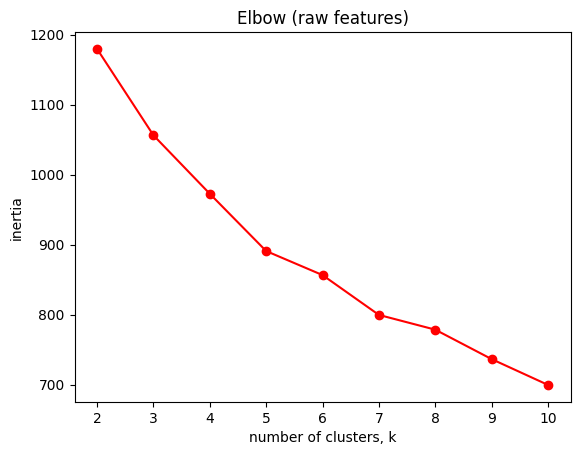

In [13]:
ks = range(2, 11)
inertias = []
for k in ks:
    ###### YOUR CODE STARTS HERE #####
    # create a KMeans instance with k clusters: model
    model = KMeans(n_clusters=k, random_state=42)

    # fit model to X
    model.fit(X)

    # append the inertia to the list of inertias
    inertias.append(model.inertia_)

    ###### YOUR CODE ENDS HERE #####

plt.plot(ks, inertias, '-o', color='red')
plt.xlabel('number of clusters, k')
plt.ylabel('inertia')
plt.xticks(ks)
plt.title("Elbow (raw features)")
plt.show()

## Train your best KMeans

Pick `best_k` from the elbow on the raw features, fit KMeans once on `X`, and save the labels. These labels are our **segments** and will be used in the PCA visualization.

In [14]:
###### YOUR CODE STARTS HERE #####
 # choose from the elbow plot
best_k = 5 # Replace with the optimal k from the elbow plot

kmeans_final = KMeans(n_clusters=best_k, random_state=42)

# fit your model
kmeans_final.fit(X)

# cluster labels
best_cluster_labels = kmeans_final.labels_
# assign labels
data['Segment'] = best_cluster_labels
best_cluster_labels
###### YOUR CODE ENDS HERE #####

array([1, 1, 3, 3, 4, 3, 3, 3, 4, 0, 4, 0, 1, 1, 1, 4, 2, 1, 4, 1, 4, 0,
       3, 3, 2, 1, 1, 2, 3, 1, 1, 1, 4, 0, 3, 2, 2, 3, 1, 3, 0, 3, 0, 0,
       0, 3, 3, 2, 0, 1, 0, 1, 4, 2, 3, 3, 1, 2, 1, 4, 1, 3, 3, 3, 2, 2,
       2, 3, 2, 3, 3, 1, 0, 1, 2, 4, 2, 1, 3, 0, 2, 2, 3, 2, 2, 3, 2, 3,
       0, 0, 3, 3, 1, 1, 4, 3, 1, 2, 1, 0, 0, 3, 4, 3, 3, 1, 4, 3, 2, 4,
       0, 2, 0, 2, 1, 0, 4, 0, 2, 2, 4, 0, 4, 2, 4, 3, 3, 2, 2, 3, 2, 4,
       4, 4, 0, 0, 4, 4, 0, 3, 0, 3, 0, 3, 0, 0, 0, 1, 0, 4, 2, 0, 3, 0,
       0, 2, 0, 3, 4, 3, 2, 3, 0, 2, 2, 3, 1, 0, 1, 2, 0, 3, 3, 3, 2, 0,
       2, 2, 0, 3, 3, 4, 4, 2, 1, 0, 0, 3, 4, 3, 1, 1, 3, 0, 0, 3, 2, 1,
       3, 0, 1, 0, 1, 3, 2, 3, 0, 3, 2, 2, 2, 1, 0, 3, 3, 4, 3, 3, 4, 1,
       0, 2, 1, 3, 4, 3, 0, 2, 0, 1, 3, 1, 3, 3, 0, 0, 4, 0, 2, 3, 1, 4,
       3, 3, 3, 2, 3, 4, 2, 0, 2, 3, 1, 1, 3, 0, 3, 0, 2, 4, 2, 4, 0, 4,
       3, 4, 1, 4, 0, 4, 0, 2, 1, 1, 4, 3, 2, 0, 3, 0, 2, 2, 1, 4, 0, 3,
       4, 0, 2, 0, 1, 3, 3, 3, 3, 2, 3, 2, 2, 0, 3,

# Exercise: PCA

## Dimensionality Reduction using Principal Component Analysis (PCA)

[Principal Component Analysis (PCA)](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html) creates new features called principal components that capture most of the variation in the data. We will use it here for two purposes: **data visualization** and **data compression for clustering**. In both cases we start from the same feature matrix `X`.


## PCA for Data Visualization

Project the TripAdvisor features `X` onto the first two principal components (PC1, PC2). Plot PC1 vs PC2 and color the travelers using the **best cluster labels** from the previous exercise. This step is only for visualization and does not change the clusters.

In [15]:
from sklearn.decomposition import PCA
import seaborn as sns

###### YOUR CODE STARTS HERE #####

# create a PCA instance with the suggested number of components
pca = PCA(n_components=2, random_state=42)

# project X into the 2D PCA space
X_pca2 = pca.fit_transform(X)

# save components to a DataFrame
PCA_components = pd.DataFrame(X_pca2, columns=["PC1", "PC2"])

###### YOUR CODE ENDS HERE #####

### Plot clusters on PCA

Use the 2D PCA scores you just computed. Color points with the **best KMeans labels** from before.

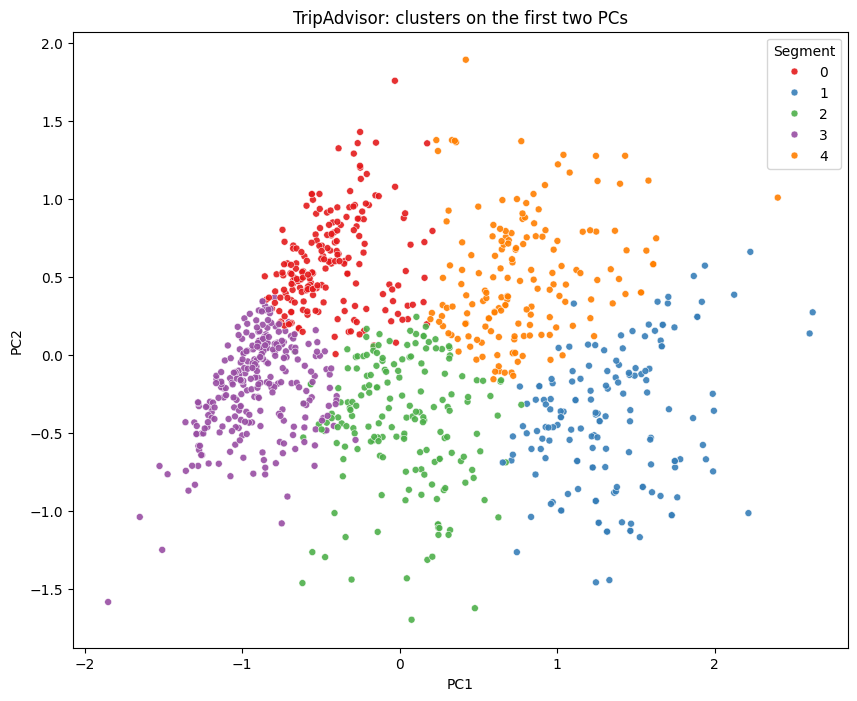

In [16]:
# build plotting frame from the 2D PCA scores
df_pca_kmeans = PCA_components.copy()

###### YOUR CODE STARTS HERE #####

# Assign the labels to the PCA_components
df_pca_kmeans["Segment"] = best_cluster_labels

plt.figure(figsize=(10, 8))
sns.scatterplot(
    x="PC1",
    y="PC2",
    hue="Segment",
    data=df_pca_kmeans,
    palette="Set1", s=25, alpha=0.9
)

###### YOUR CODE ENDS HERE #####
plt.title("TripAdvisor: clusters on the first two PCs")
plt.legend(title="Segment", loc="best")
plt.show()

## PCA for Data Compression

We use PCA here to **keep most of the information while dropping noise and correlation**. PCA orders the new features (PC1, PC2, …) by how much variance they capture. The **cumulative explained variance** tells us how much of the original variation we have kept after the first m PCs.

- **m90** is the smallest number of components that keeps **90%** of the total variance.  
- **m95** is the smallest number that keeps **95%**.

Pick m to balance **fidelity** and **simplicity**. Around 90–95% is a common target. After choosing m, we will fit KMeans in this **m-dimensional PCA space**. The clusters may become tighter because PCA removes redundant directions. If m is too small, separation can get worse, so this choice is a trade-off.


m90 = 6, m95 = 7


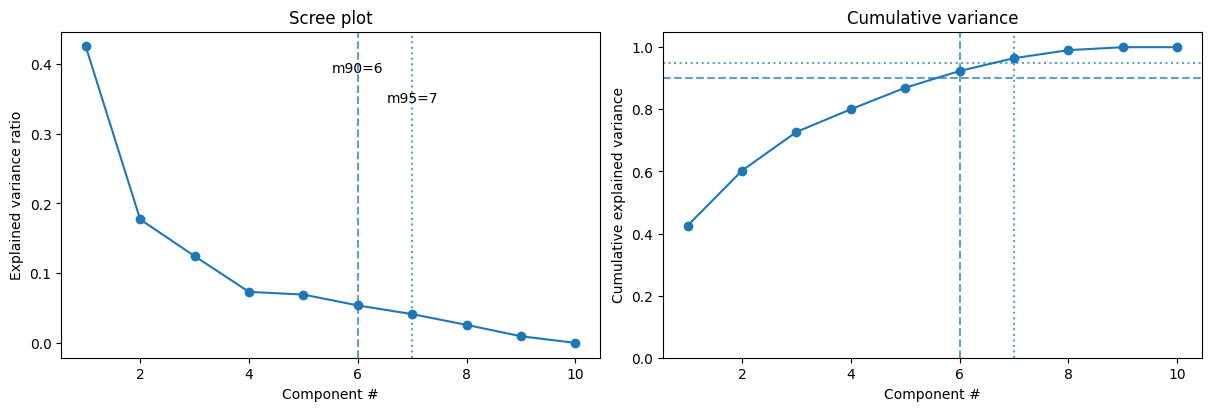

In [17]:
# Fit PCA once on X to get variance info
pca_full = PCA().fit(X)

# Per-component variance share and its cumulative sum
var_ratio = pca_full.explained_variance_ratio_
cum_var = np.cumsum(var_ratio)

# Smallest m reaching 90% and 95% cumulative variance
m90 = int(np.argmax(cum_var >= 0.90) + 1)
m95 = int(np.argmax(cum_var >= 0.95) + 1)


# Side-by-side: Scree (per-PC) and Cumulative variance
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)

# Scree plot: how much each PC contributes
axes[0].plot(range(1, len(var_ratio)+1), var_ratio, "o-")
axes[0].set_title("Scree plot")
axes[0].set_xlabel("Component #")
axes[0].set_ylabel("Explained variance ratio")
axes[0].axvline(m90, linestyle="--", alpha=0.7)
axes[0].axvline(m95, linestyle=":",  alpha=0.7)
axes[0].text(m90, max(var_ratio)*0.95, f"m90={m90}", ha="center", va="top")
axes[0].text(m95, max(var_ratio)*0.85, f"m95={m95}", ha="center", va="top")

# Cumulative variance: how much total variance is kept up to m
axes[1].plot(range(1, len(cum_var)+1), cum_var, "o-")
axes[1].set_title("Cumulative variance")
axes[1].set_xlabel("Component #")
axes[1].set_ylabel("Cumulative explained variance")
axes[1].axhline(0.90, linestyle="--", alpha=0.7)
axes[1].axhline(0.95, linestyle=":",  alpha=0.7)
axes[1].axvline(m90, linestyle="--", alpha=0.7)
axes[1].axvline(m95, linestyle=":",  alpha=0.7)
axes[1].set_ylim(0, 1.05)

print(f"m90 = {m90}, m95 = {m95}")


### KMeans after PCA (compression)
Use the number of components you just chose (e.g., **m90**) to compress `X` and train KMeans in this m-dimensional PCA space. Reuse your `best_k` from the elbow; this yields a new set of labels, `labels_pca_m`, learned in the compressed space.

In [18]:
###### YOUR CODE STARTS HERE #####
# pick the smallest m hitting ~90% cumulative variance for modeling dimension (m)
n_components_model = m90

# Fit PCA for modeling and transform X into m-dimensional space
pca_model = PCA(n_components=n_components_model, random_state=42)
Z_model = pca_model.fit_transform(X)

# Fit KMeans in the PCA(m) space using your best_k
kmeans_pca_m = KMeans(n_clusters=best_k, random_state=42)
kmeans_pca_m.fit(Z_model)

# Cluster labels learned in PCA(m) space
labels_pca_m = kmeans_pca_m.labels_
###### YOUR CODE ENDS HERE #####

### Side-by-side comparison on PC1–PC2
We now show the same PC1–PC2 coordinates twice: left colored by the raw-X KMeans labels, right colored by the PCA(m) labels.

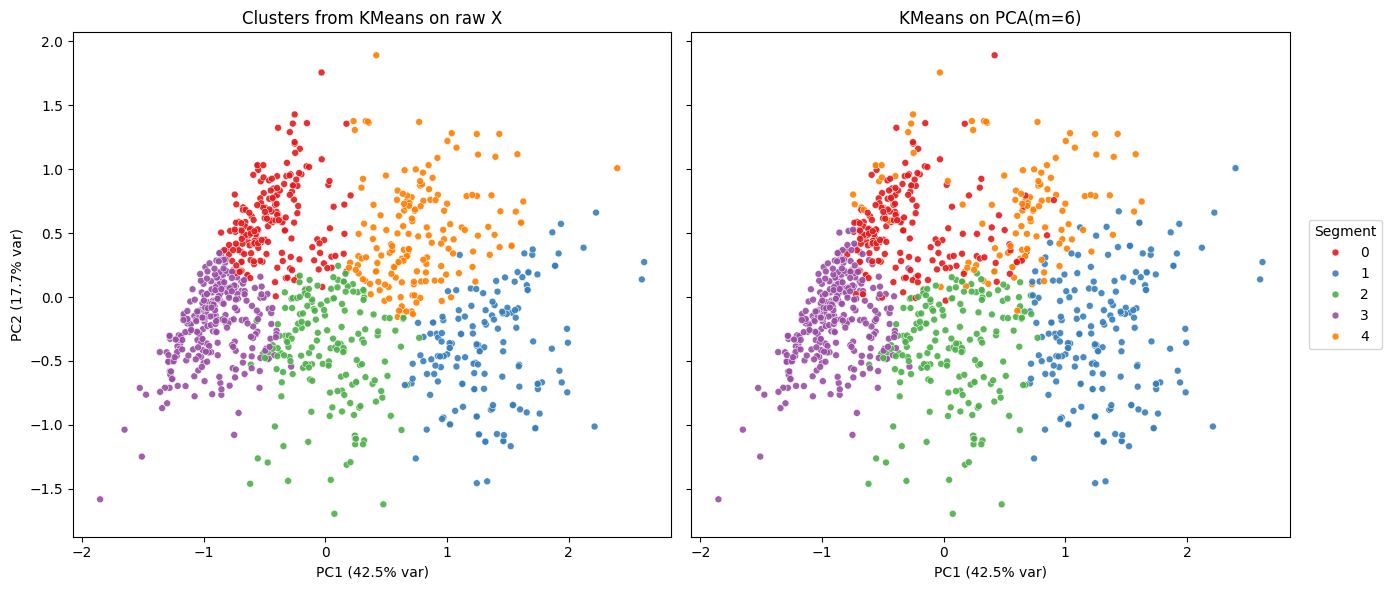

In [19]:
# Side-by-side: (left) labels from KMeans on raw X  vs  (right) labels from KMeans on PCA(m)
from sklearn.metrics.cluster import contingency_matrix
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)

# Build a 1-1 mapping from PCA(m) label -> raw-X label using a greedy match
C = contingency_matrix(best_cluster_labels, labels_pca_m)
C_work = C.copy()
mapping = {}
for _ in range(min(C_work.shape)):
    i, j = divmod(C_work.argmax(), C_work.shape[1])
    mapping[j] = i
    C_work[i, :] = -1
    C_work[:, j] = -1
labels_pca_m_aligned = np.array([mapping.get(l, l) for l in labels_pca_m])

# Consistent color mapping for cluster ids 0..best_k-1
hue_order = list(range(best_k))

# Left: raw-X KMeans labels
sns.scatterplot(
    x="PC1", y="PC2",
    hue="Segment",
    data=PCA_components.assign(Segment=best_cluster_labels),
    hue_order=hue_order, palette="Set1", s=25, alpha=0.9, ax=axes[0]
)
axes[0].set_title("Clusters from KMeans on raw X")
axes[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% var)")
axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% var)")

# Right: labels from KMeans on PCA(m), aligned to raw-X ids for consistent colors
sns.scatterplot(
    x="PC1", y="PC2",
    hue="Segment",
    data=PCA_components.assign(Segment=labels_pca_m_aligned),
    hue_order=hue_order, palette="Set1", s=25, alpha=0.9, ax=axes[1]
)
axes[1].set_title(f"KMeans on PCA(m={n_components_model})")
axes[1].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% var)")
axes[1].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% var)")

# Single legend outside
handles, labels = axes[1].get_legend_handles_labels()
if axes[0].legend_ is not None:
    axes[0].legend_.remove()
axes[1].legend(handles=handles, title="Segment", loc="center left", bbox_to_anchor=(1.02, 0.5))

plt.tight_layout()
plt.show()


#### **Ungraded**
In the side-by-side plots, do any clusters look mixed or overlapping? Give one reason that could explain it e.g., the 2D projection hides separation, `m` is too small, `k` isn’t ideal, or KMeans prefers roughly spherical clusters

**Ungraded Answer:**

We can verify with a metric: compute the [`silhouette score`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html) in each model’s own space. Higher is better; ~0.0 is poor, ~0.2–0.5 is reasonable, >0.5 is strong.

In [20]:
from sklearn.metrics import silhouette_score
print(f"Silhouette on raw X: {silhouette_score(X, best_cluster_labels):.4f}")
print(f"Silhouette on PCA(m={n_components_model}): {silhouette_score(Z_model, labels_pca_m):.4f}")


Silhouette on raw X: 0.1640
Silhouette on PCA(m=6): 0.1906
